01. create Linear Regression to load data

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

df = pd.read_csv("train.csv")

02. Seperate Features (X) from the target (Y)

In [4]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]
print(X.shape, y.shape)

(20640, 8) (20640,)


03. Train/test split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(16512, 8) (4128, 8)


04. Baseline,The Dumbest Model

In [8]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)

print("MAE :", mean_absolute_error(y_test, base_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, base_pred)))
print("R2 :",r2_score(y_test,base_pred))

MAE : 0.9060685490007149
RMSE: 1.1448563543099792
R2 : -0.00021908714592466794


05. Train Linear Regression

In [9]:
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

06. Measure it

In [10]:
mae =mean_absolute_error(y_test,pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)
print(f"MAE : {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2  : {r2:.3f}")

MAE : 0.533
RMSE: 0.746
R2  : 0.576


07. Look at what the model learned

In [11]:
coef = pd.Series(model.coef_, index=X.columns).sort_values()
print(coef)
print("Intercept:", model.intercept_)

Longitude    -0.433708
Latitude     -0.419792
AveRooms     -0.123323
AveOccup     -0.003526
Population   -0.000002
HouseAge      0.009724
MedInc        0.448675
AveBedrms     0.783145
dtype: float64
Intercept: -37.023277706064256


08. Predicted vs actual chart

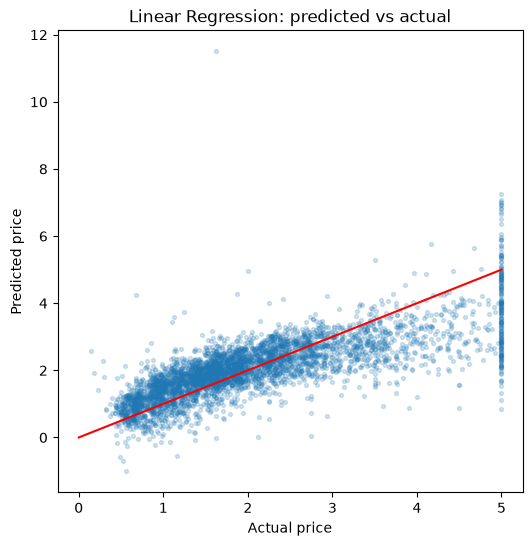

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.2, s=8)
plt.plot([0, 5], [0, 5], color="red")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Linear Regression: predicted vs actual")
plt.show()